# EDA

Exploring the term deposit marketing data before modeling.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parents[1]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.data.load_data import load_raw_data
from src.utils.config import TARGET_COL

sns.set_theme(style="whitegrid")

In [3]:
df = load_raw_data()
df.shape

(40000, 14)

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,no


What each column means:
- age, job, marital, education: customer background
- default: has credit in default
- balance: average yearly balance in euros
- housing, loan: has a housing loan / personal loan
- contact: how they were contacted
- day, month: date of the last contact
- duration: length of the last call in seconds
- campaign: number of calls to this customer during the campaign, including the last one
- y: subscribed to a term deposit

## Data quality check

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        40000 non-null  int64
 1   job        40000 non-null  str  
 2   marital    40000 non-null  str  
 3   education  40000 non-null  str  
 4   default    40000 non-null  str  
 5   balance    40000 non-null  int64
 6   housing    40000 non-null  str  
 7   loan       40000 non-null  str  
 8   contact    40000 non-null  str  
 9   day        40000 non-null  int64
 10  month      40000 non-null  str  
 11  duration   40000 non-null  int64
 12  campaign   40000 non-null  int64
 13  y          40000 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.3 MB


In [6]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
y            0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

The dataset has 40,000 rows, with no null values or duplicate rows. There is no customer ID, so the same customer could still appear multiple times.

In [8]:
{col: sorted(df[col].unique()) for col in df.select_dtypes(include="str").columns}

{'job': ['admin',
  'blue-collar',
  'entrepreneur',
  'housemaid',
  'management',
  'retired',
  'self-employed',
  'services',
  'student',
  'technician',
  'unemployed',
  'unknown'],
 'marital': ['divorced', 'married', 'single'],
 'education': ['primary', 'secondary', 'tertiary', 'unknown'],
 'default': ['no', 'yes'],
 'housing': ['no', 'yes'],
 'loan': ['no', 'yes'],
 'contact': ['cellular', 'telephone', 'unknown'],
 'month': ['apr',
  'aug',
  'dec',
  'feb',
  'jan',
  'jul',
  'jun',
  'mar',
  'may',
  'nov',
  'oct'],
 'y': ['no', 'yes']}

In [9]:
unknown_counts = (df == "unknown").sum()

unknown_summary = pd.DataFrame({
    "count": unknown_counts,
    "percent": (unknown_counts / len(df) * 100).round(1),
})

unknown_summary[unknown_summary["count"] > 0]

,count,percent
job,235,0.6
education,1531,3.8
contact,12765,31.9


Some information is recorded as "unknown". "Unknown" appears most often in contact (32%), followed by education (4%) and job (under 1%). The contact method may not have been recorded, and customers may not have provided their job or education details. "Unknown" is being kept as its own category.

In [10]:
months = ["jan", "feb", "mar", "apr", "may", "jun",
          "jul", "aug", "sep", "oct", "nov", "dec"]

df["month"].value_counts().reindex(months, fill_value=0)

month
jan     1176
feb     2296
mar      258
apr     2718
may    13532
jun     4734
jul     6380
aug     5215
sep        0
oct       80
nov     3598
dec       13
Name: count, dtype: int64

There are no September records. October has 80 rows and December has only 13, so subscription rates for those months rely on very few customers.

In [11]:
df.describe()

,age,balance,day,duration,campaign
count,40000.000000,40000.000000,40000.000000,40000.000000,40000.000000
mean,40.544600,1274.277550,16.017225,254.824300,2.882175
std,9.641776,2903.769716,8.278127,259.366498,3.239051
min,19.000000,-8019.000000,1.000000,0.000000,1.000000
25%,33.000000,54.000000,8.000000,100.000000,1.000000
50%,39.000000,407.000000,17.000000,175.000000,2.000000
75%,48.000000,1319.000000,21.000000,313.000000,3.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000


In [12]:
negative_balance = df["balance"] < 0

pd.DataFrame({
    "count": negative_balance.value_counts(),
    "percent": negative_balance.value_counts(normalize=True).mul(100).round(1),
})

,count,percent
balance,,
False,36269,90.7
True,3731,9.3


- Ages range from 19 to 95, and the average age is 40.5. There is no impossible age value.
- The day of last contact ranges from 1 to 31. These fall within the possible days of a month.
- Customers were contacted an average of 2.88 times during the campaign. The median is 2, and at least 75% of records have 3 or fewer contacts.
- The average last-call duration is about 255 seconds, or 4 minutes and 15 seconds. The median is lower at 175 seconds.
- Balance ranges from -8,019 to 102,127 euros, with a median of 407 euros. About 9.3% of rows have a negative balance, meaning the account was overdrawn on average. The max is far above the 75th percentile (1,319 euros) but still possible, so it stays.

In [13]:
df.skew(numeric_only=True).round(1)

age         0.4
balance     8.3
day         0.1
duration    3.2
campaign    4.7
dtype: float64

balance, duration, and campaign are all right-skewed, so the median is a better summary than the mean for them.

In [14]:
df.loc[df["duration"] == 0, ["duration", TARGET_COL]]

,duration,y
6424,0,no
22937,0,no
36425,0,no


Three calls have a recorded duration of zero, and all three have a subscription outcome of "no". These are probably unanswered calls or instant hang-ups.

## Target

In [15]:
pd.DataFrame({
    "count": df[TARGET_COL].value_counts(),
    "percent": df[TARGET_COL].value_counts(normalize=True).mul(100).round(1),
})

,count,percent
y,,
no,37104,92.8
yes,2896,7.2


92.8% of customers did not subscribe (y = "no") and 7.2% did (y = "yes"), about 13 "no" for every "yes". The classes are heavily imbalanced. A model that always predicts "no" would achieve 92.8% accuracy, which is above the 81% target, yet would never find a single subscriber. So accuracy alone cannot judge the models.


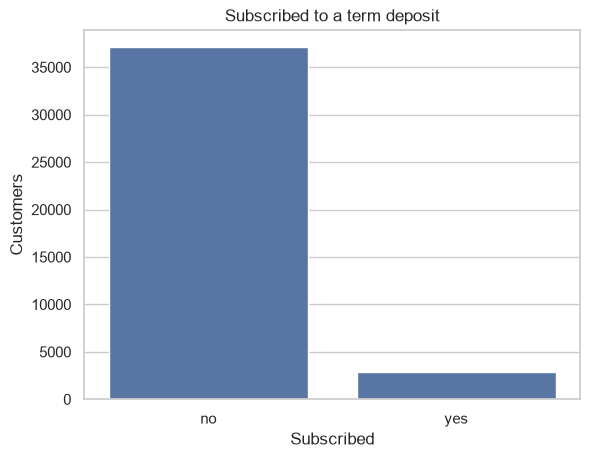

In [16]:
sns.countplot(x=TARGET_COL, data=df, order=["no", "yes"])
plt.title("Subscribed to a term deposit")
plt.xlabel("Subscribed")
plt.ylabel("Customers")
plt.savefig(project_root / "reports" / "figures" / "target_balance.png", bbox_inches="tight")
plt.show()

The class that matters is "yes". Recall shows how many actual subscribers the model finds, and precision shows how many of the customers it flags actually subscribe (low precision means wasted calls). Splits and CV folds need to be stratified so each one keeps the 7.2% share of "yes".

## Feature distributions

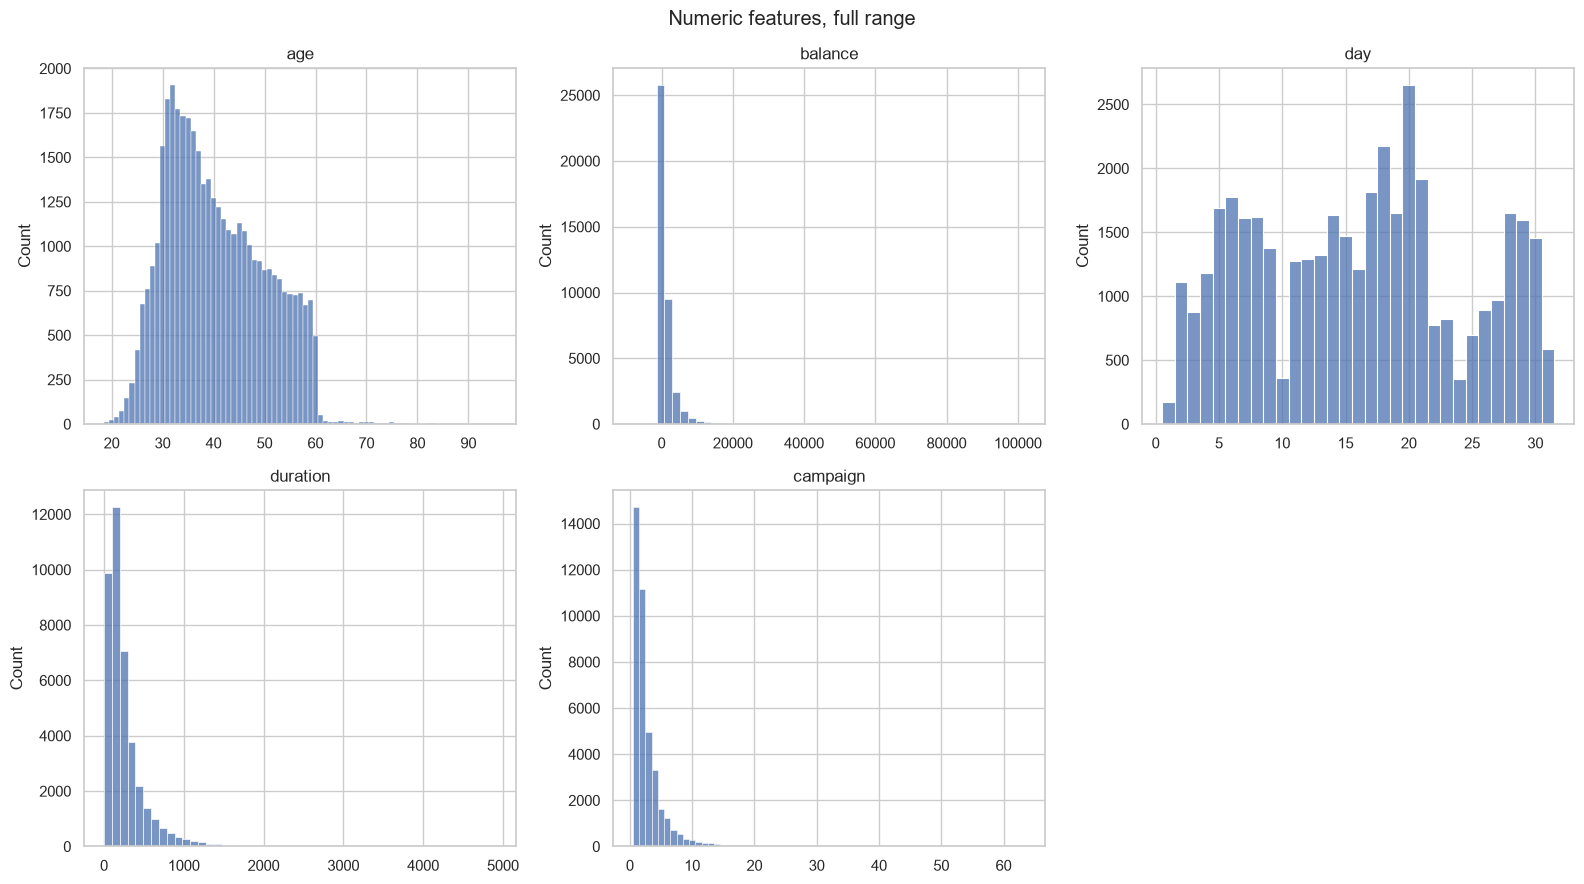

In [18]:
numeric_cols = df.select_dtypes(include="number").columns
discrete_cols = ["age", "day", "campaign"]

fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axs.flat, numeric_cols):
    sns.histplot(df[col], bins=50, discrete=col in discrete_cols, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
axs.flat[-1].set_visible(False)
fig.suptitle("Numeric features, full range")
fig.tight_layout()
plt.show()

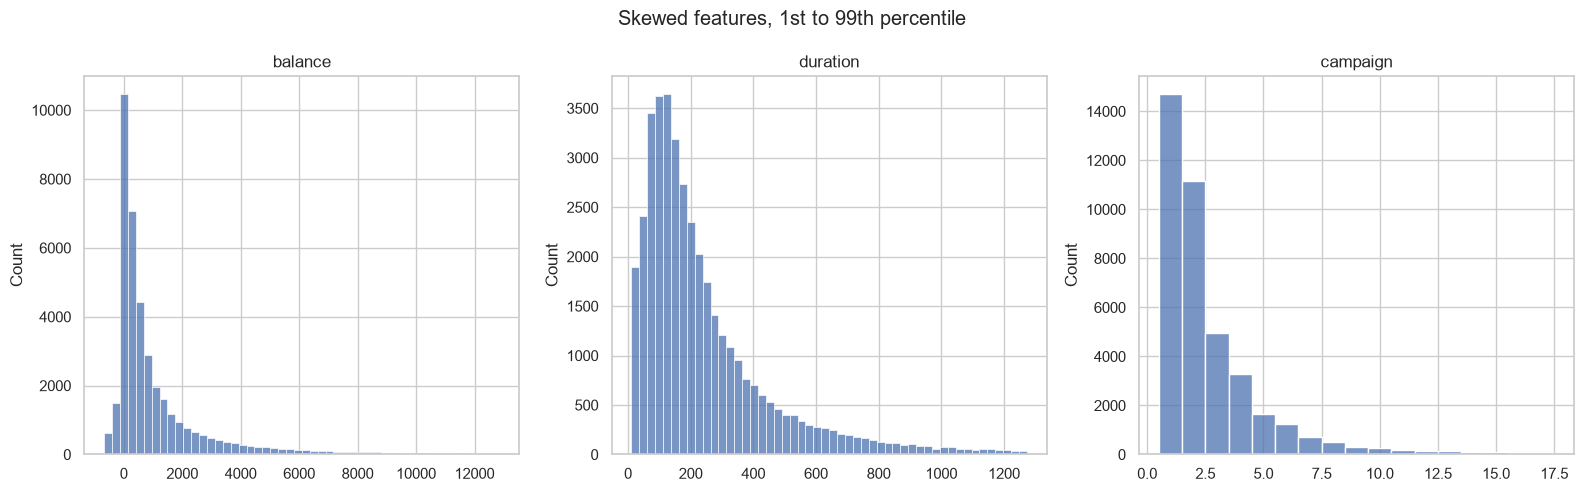

In [19]:
skewed_cols = ["balance", "duration", "campaign"]

fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axs, skewed_cols):
    low, high = df[col].quantile([0.01, 0.99])
    sns.histplot(df.loc[df[col].between(low, high), col], bins=50, discrete=col in discrete_cols, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Skewed features, 1st to 99th percentile")
fig.tight_layout()
plt.show()

In [20]:
(df["balance"] == 0).mean()

np.float64(0.080225)

In [21]:
df.loc[df["job"] == "retired", "age"].describe()

count    1437.000000
mean       57.185108
std         7.064307
min        24.000000
25%        55.000000
50%        58.000000
75%        59.000000
max        95.000000
Name: age, dtype: float64

In [22]:
(df.loc[df["job"] == "retired", "age"] > 60).sum()

np.int64(163)

In [23]:
df["campaign"].value_counts(normalize=True).sort_index().cumsum().mul(100).round(1).head()

campaign
1    36.8
2    64.7
3    77.1
4    85.3
5    89.4
Name: proportion, dtype: float64

In [24]:
df["day"].value_counts().head()

day
20    2655
18    2173
21    1914
17    1812
6     1778
Name: count, dtype: int64

- Most customers are between about 25 and 60, and very few are over 60. Retirement does not explain the drop, since 1,437 customers are retired and have a median age of 58. Only 163 of them are over 60. The cutoff likely reflects how customers were selected for the campaign, so the model will not know much about customers over 60.
- 8% of customers have a balance of exactly 0, which is the spike at 0. Most balances are small: the 25th percentile is 54 euros, and the median is 407 euros.
- Calls are spread over the whole month but not evenly. The 20th is the busiest day.
- Most calls are short, and only a small share run much longer.
- 37% of customers were called once, and 77% were called 3 times or fewer.

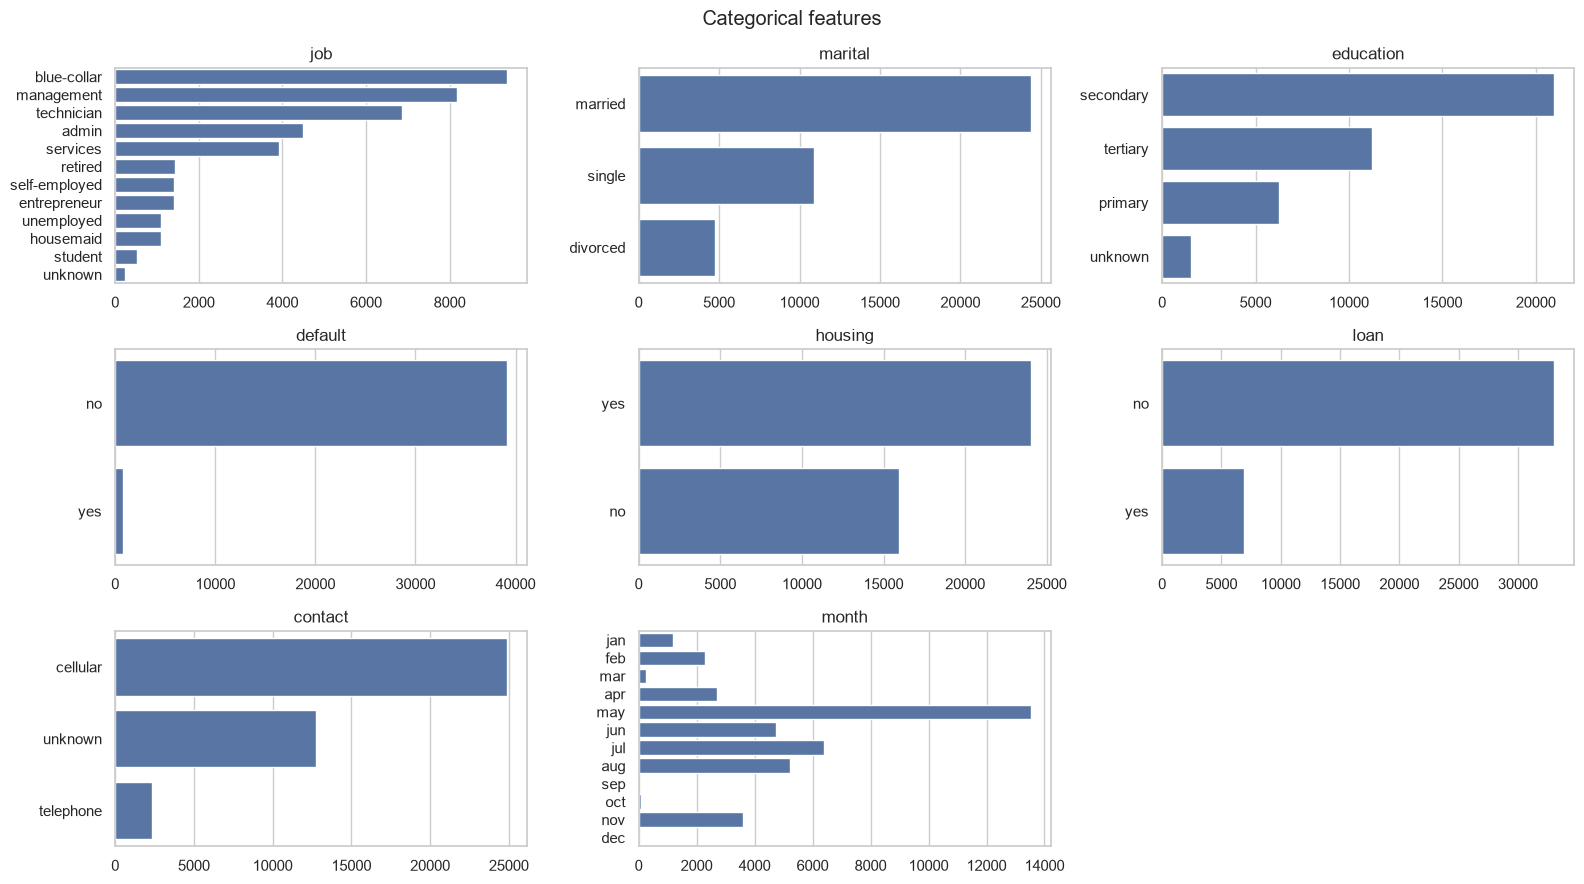

In [ ]:
categorical_cols = df.select_dtypes(include="str").columns.drop(TARGET_COL)

fig, axs = plt.subplots(3, 3, figsize=(16, 9))
for ax, col in zip(axs.flat, categorical_cols):
    order = months if col == "month" else df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axs.flat[-1].set_visible(False)
fig.suptitle("Categorical features")
fig.tight_layout()
plt.show()

In [ ]:
{col: df[col].value_counts(normalize=True).mul(100).round(1).head() for col in categorical_cols}

{'job': job
 blue-collar    23.5
 management     20.4
 technician     17.1
 admin          11.2
 services        9.8
 Name: proportion, dtype: float64,
 'marital': marital
 married     61.0
 single      27.2
 divorced    11.8
 Name: proportion, dtype: float64,
 'education': education
 secondary    52.5
 tertiary     28.0
 primary      15.7
 unknown       3.8
 Name: proportion, dtype: float64,
 'default': default
 no     98.0
 yes     2.0
 Name: proportion, dtype: float64,
 'housing': housing
 yes    60.1
 no     39.9
 Name: proportion, dtype: float64,
 'loan': loan
 no     82.7
 yes    17.3
 Name: proportion, dtype: float64,
 'contact': contact
 cellular     62.3
 unknown      31.9
 telephone     5.8
 Name: proportion, dtype: float64,
 'month': month
 may    33.8
 jul    16.0
 aug    13.0
 jun    11.8
 nov     9.0
 Name: proportion, dtype: float64}

- The most common jobs are blue-collar, management, and technician. Housemaid, student, and unemployed are among the least common.
- Most customers are married (61%).
- Secondary (roughly high school level) is the most common education level.
- Only 2% of customers have credit in default, so `default` is almost all "no" and probably will not help the model much.
- 60% of customers have a housing loan, and 83% do not have a personal loan.
- Most customers were called on a cell phone (62%).
- May stands out, accounting for 34% of all last contacts

## Features vs. target

In [ ]:
df.groupby(TARGET_COL)[numeric_cols].median()

,age,balance,day,duration,campaign
y,,,,,
no,39.0,395.0,17.0,164.0,2.0
yes,37.0,620.0,16.0,629.0,2.0


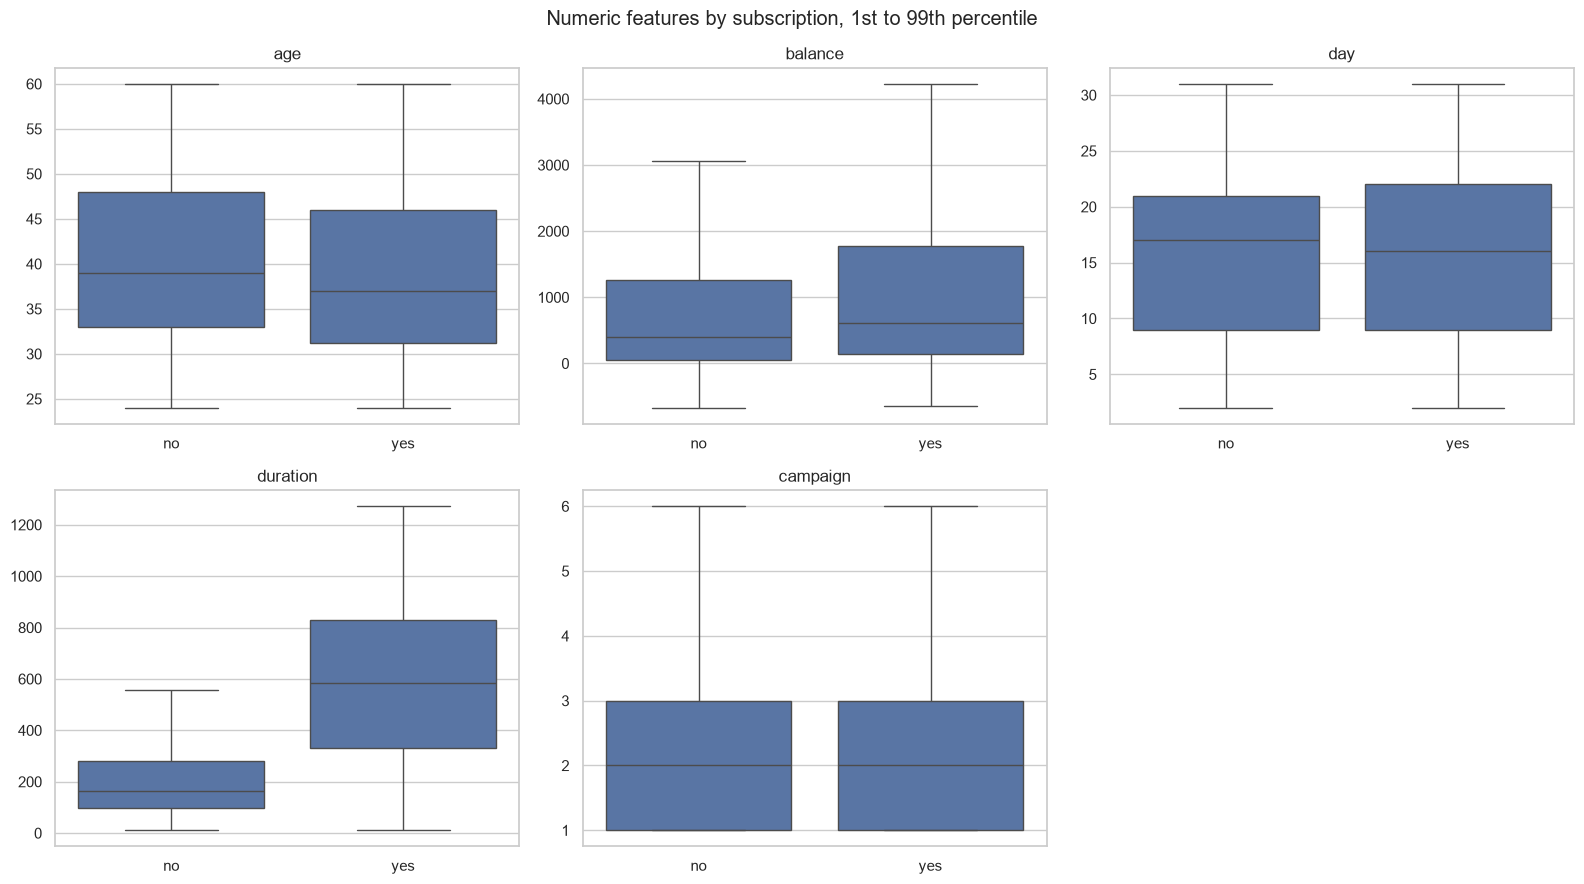

In [28]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axs.flat, numeric_cols):
    low, high = df[col].quantile([0.01, 0.99])
    sns.boxplot(x=TARGET_COL, y=col, data=df[df[col].between(low, high)], order=["no", "yes"], showfliers=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axs.flat[-1].set_visible(False)
fig.suptitle("Numeric features by subscription, 1st to 99th percentile")
fig.tight_layout()
plt.show()

- The median last call lasted 629 seconds for subscribers and 164 seconds for non-subscribers. Duration is only known after the call ends, and a customer who is interested stays on the line longer, so the models will be trained with and without it.
- The median balance is 620 for subscribers and 395 for non-subscribers, but the boxes overlap a lot, so balance on its own probably separates the groups only weakly.
- Median age is 37 for subscribers and 39 for non-subscribers. Students and retired customers have the two highest job rates in the category chart below, and they are at opposite ends of the age range, so the medians end up close.
- The box plots for `campaign` and day of the month look the same for both groups.

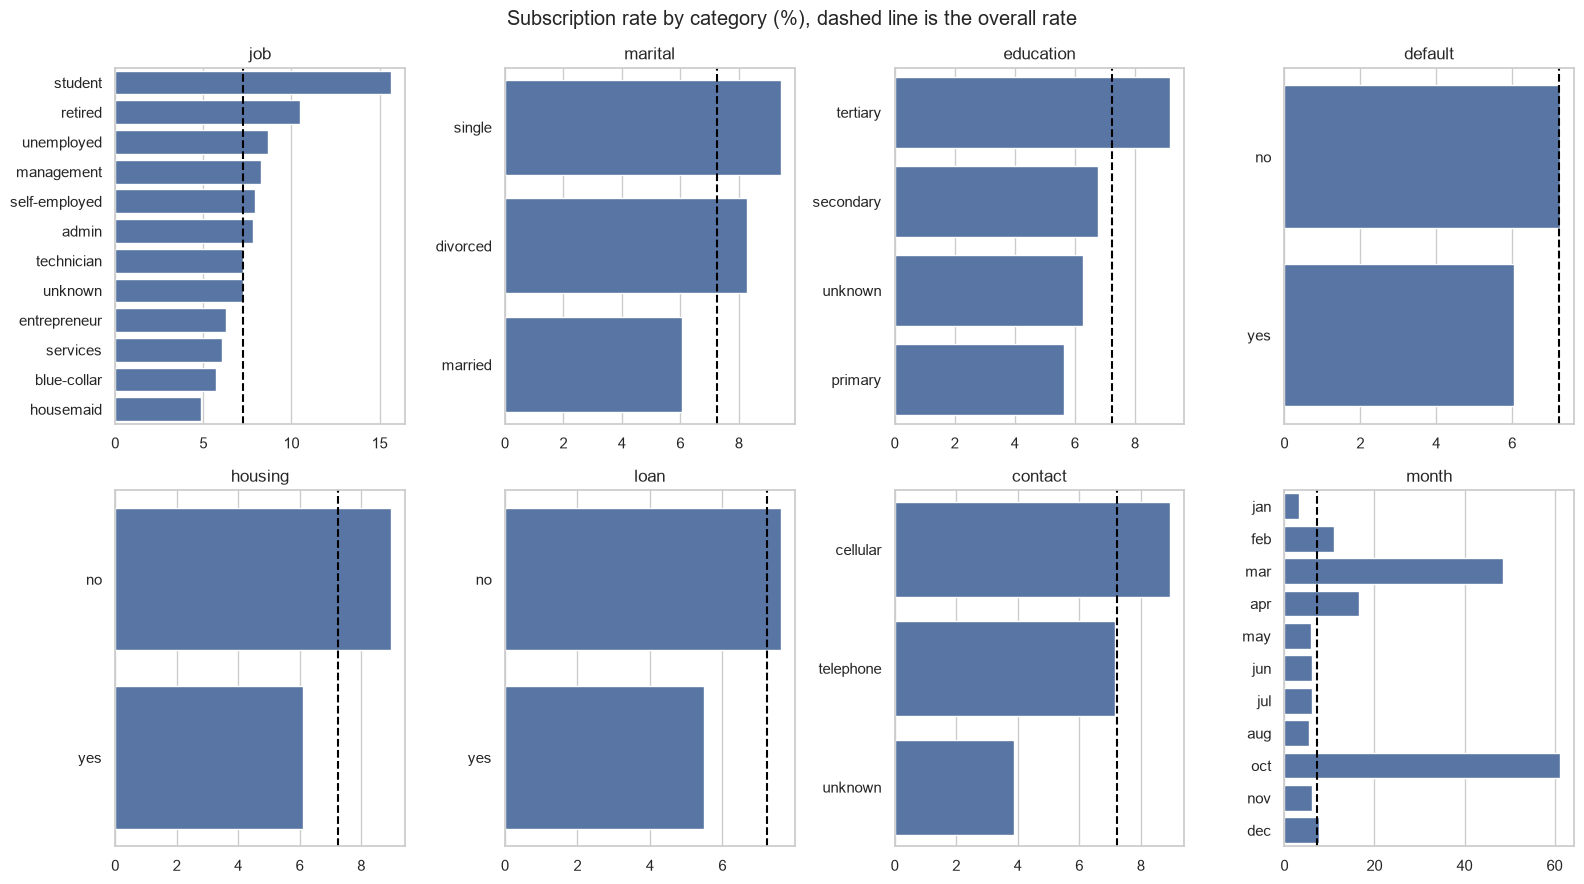

In [29]:
subscribed = df[TARGET_COL].eq("yes")
overall_rate = subscribed.mean() * 100

fig, axs = plt.subplots(2, 4, figsize=(16, 9))
for ax, col in zip(axs.flat, categorical_cols):
    rate = subscribed.groupby(df[col]).mean().mul(100)
    rate = rate.reindex(months).dropna() if col == "month" else rate.sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax)
    ax.axvline(overall_rate, color="black", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Subscription rate by category (%), dashed line is the overall rate")
fig.tight_layout()
plt.show()

In [30]:
{col: pd.DataFrame({
    "customers": df[col].value_counts(),
    "rate": subscribed.groupby(df[col]).mean().mul(100).round(1),
}).sort_values("rate", ascending=False) for col in categorical_cols}

{'job':                customers  rate
 job                           
 student              524  15.6
 retired             1437  10.5
 unemployed          1104   8.7
 management          8166   8.3
 self-employed       1414   7.9
 admin               4483   7.8
 technician          6852   7.3
 unknown              235   7.2
 entrepreneur        1405   6.3
 services            3910   6.1
 blue-collar         9383   5.7
 housemaid           1087   4.9,
 'marital':           customers  rate
 marital                  
 single        10889   9.4
 divorced       4725   8.3
 married       24386   6.1,
 'education':            customers  rate
 education                 
 tertiary       11206   9.2
 secondary      20993   6.8
 unknown         1531   6.3
 primary         6270   5.6,
 'default':          customers  rate
 default                 
 no           39191   7.3
 yes            809   6.1,
 'housing':          customers  rate
 housing                 
 no           15969   9.0
 yes      

- October (61.3%) and March (48.4%) have the highest subscription rates, but only 80 and 258 customers were last contacted in those months. With groups that small, a few subscribers change the rate a lot. May had 13,532 customers and a rate of 5.8%.
- Customers with an unknown contact type subscribe at 3.9%, compared with 9.0% for cellular. The gap is large, so keeping "unknown" as its own category makes sense.
- Students are one of the least common jobs but have the highest subscription rate (15.6%). Retired customers subscribe at 10.5%, above the overall rate of 7.2%. Blue-collar, the largest group, is below it at 5.7%.
- Customers with a loan subscribe less often. Customers with a housing loan subscribe at 6.1%, compared with 9.0% for those without one. Personal loans show the same pattern.
- `default` has the smallest gap of the yes/no columns (6.1% vs. 7.3%), and only 809 customers have defaulted.

## Feature relationships

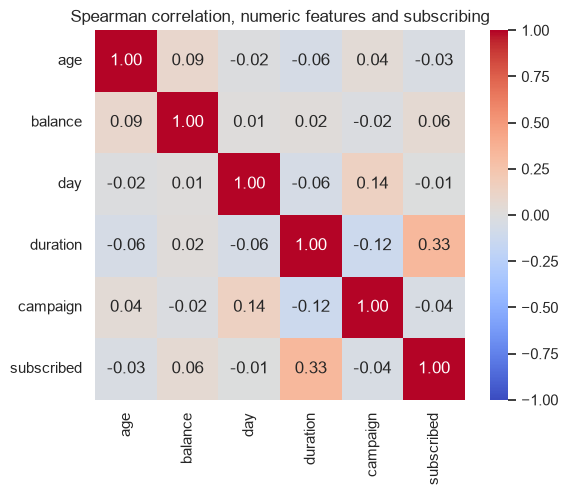

In [31]:
sns.heatmap(df[numeric_cols].assign(subscribed=subscribed).corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation, numeric features and subscribing")
plt.show()

- No two numeric features are strongly correlated. The largest value is 0.14, between day and campaign.
- Duration has the strongest correlation with subscribing (0.33). Balance is next at 0.06, and the rest are close to 0.

## Summary

The data has 40,000 customers with no missing values or duplicate rows. "Unknown" appears in contact, education, and job. It will be kept as its own category.

Main findings:
- Only 7.2% of customers subscribed. A model that always predicts "no" scores 92.8% accuracy, which is already above the 81% target.
- Duration separates the groups most (median 629 seconds for subscribers vs. 164 for non-subscribers, correlation 0.33), but it is only known after the call ends.
- Students (15.6%) and retired customers (10.5%) subscribe well above the overall rate. Customers called on a cell phone and customers without a housing loan are also above it (9.0% each).
- Customers with an unknown contact type subscribe at 3.9%, the lowest of the contact groups.
- October and March have the highest monthly rates, but only 80 and 258 customers were contacted in those months, so those rates are not reliable.
- `default`, `campaign`, and day of the month show little difference between subscribers and non-subscribers.
- No pair of numeric features is strongly correlated (the largest is 0.14).